# Part 1: CNNs

Attach the soil competition data and the `denysmykhailov/soil-cv-utils` dataset (version 3).
Select 2 x T4 GPUs, turn Internet on, and allow the `WANDB_API_KEY` secret.
Then use Save Version → Save & Run All.

All code comes from the code dataset. No local helper files are needed.
W&B tracks each fold in `public-team/soil-grain-size`. There are no CV-summary runs.
At the end, Kaggle Outputs has `submission.csv` and `part1_cnn/` with the full study.


In [1]:
from pathlib import Path
import json
import os
import sys
import subprocess

code_root = Path(os.environ.get(
    'SOILCV_UTILS_ROOT', '/kaggle/input/datasets/denysmykhailov/soil-cv-utils'
))
if not (code_root/'soilcv/cnn/experiments.py').is_file():
    matches = list(Path('/kaggle/input').rglob('soilcv/cnn/experiments.py'))
    if len(matches) != 1:
        raise RuntimeError('Attach the latest soil-cv-utils dataset with soilcv/cnn/.')
    code_root = matches[0].parents[2]
sys.path.insert(0, str(code_root))
os.environ['PYTHONPATH'] = str(code_root) + os.pathsep + os.environ.get('PYTHONPATH', '')
os.environ['TORCH_HOME'] = '/tmp/soilcv-torch'
os.environ['WANDB_CACHE_DIR'] = '/tmp/soilcv-wandb-cache'
os.environ['WANDB_MODE'] = 'online'

from kaggle_secrets import UserSecretsClient
os.environ['WANDB_API_KEY'] = UserSecretsClient().get_secret('WANDB_API_KEY')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from soilcv.cnn.experiments import ROOT, RECIPES, prepare
from soilcv.cnn.analysis import (
    collect_results, plot_scores, plot_learning, plot_failures,
    hypothesis_outcomes, write_report, interpret_results,
)
from soilcv.cnn.outputs import save_source, export_outputs
from soilcv.artifacts import package_identity

if torch.cuda.device_count() != 2:
    raise RuntimeError('Select GPU T4 x2 before Run All.')
plt.style.use('seaborn-v0_8-whitegrid')
ROOT.mkdir(parents=True,exist_ok=True)
print('GPUs:', [torch.cuda.get_device_name(i) for i in range(2)])
print('Code dataset:', code_root)
print('soilcv:', package_identity())
print('Outputs:', ROOT.parent)


GPUs: ['Tesla T4', 'Tesla T4']
Code dataset: /kaggle/input/datasets/denysmykhailov/soil-cv-utils
soilcv: {'version': '0.1.1', 'source_hash': 'cd6b75b11fc58f4edefc6aed0441d246279aaa09d60be1071a569813aa8f515f', 'folds_hash': '057fe8f93ba35d2ab7a3483063c95ca0079c4bcbb9978671c16ffc4119d9c1b2'}
Outputs: /kaggle/working


## 1. Data and folds

There are only 24 train soil samples. Photos of one soil stay in one fold.
Tiles are 64 mm using estimated PPM. Absolute scale is still not verified.
The common cache uses 288 px. The 224 px recipe resizes the same view.

In [2]:
if (ROOT/'metadata.json').exists():
    saved = json.loads((ROOT/'metadata.json').read_text())
    if saved['soilcv'] != package_identity():
        raise RuntimeError('This output folder has another code version. Use a fresh session or output folder.')
else:
    prepare()
save_source()
metadata = json.loads((ROOT/'metadata.json').read_text())
labels = pd.DataFrame(json.loads((ROOT/'labels.json').read_text()))
manifest = pd.DataFrame(json.loads((ROOT/'tiles.json').read_text()))
folds = pd.read_csv(ROOT/'sample_folds.csv')
print('Train samples:', len(labels), '| Train tiles:', manifest.fold.notna().sum(), '| Test tiles:', manifest.fold.isna().sum())
display(pd.crosstab(folds.fold, labels.set_index('sample_id').loc[folds.sample_id,'soil_group'].to_numpy()))
display(pd.DataFrame(metadata['pretrained']).T)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /tmp/soilcv-torch/hub/checkpoints/resnet18-f37072fd.pth
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /tmp/soilcv-torch/hub/checkpoints/convnext_tiny-983f1562.pth
Prepared 24 train samples and 486 tiles.
Cache: a913cb3a88fb40c1c81baa67b5fd3df435ab577560ed1f65120e84161f772dca
Train samples: 24 | Train tiles: 381 | Test tiles: 105


col_0,fine,gravel,sand
fold,,,
0,2,2,2
1,2,3,1
2,2,3,1
3,1,3,2


,enum,url,sha256
resnet18,ResNet18_Weights.IMAGENET1K_V1,https://download.pytorch.org/models/resnet18-f...,f37072fd47e89c5e827621c5baffa7500819f7896bbace...
convnext_tiny,ConvNeXt_Tiny_Weights.IMAGENET1K_V1,https://download.pytorch.org/models/convnext_t...,983f1562536e84ff750a1576fb08e54de751dbf2e17c0d...


## 2. Planned experiments

Hypotheses were saved in Git before training: commit `804c059`.
Each run uses at most 24 epochs, with early stop after six epochs without a better sample-level EMD.

We use exact ImageNet V1 weights for [ResNet-18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html) and [ConvNeXt-Tiny](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.convnext_tiny.html).
We keep their image normalization, but use our fixed physical crop instead of an extra centre crop.

In [3]:
recipe_table = pd.DataFrame(RECIPES)
display(recipe_table[['id','arch','frozen','freeze_bn','optimizer','backbone_lr','head_lr','augmentation','schedule','pixels']])
print('Hypotheses commit:', metadata['hypotheses_commit'])
print('Torch:', metadata['torch'], '| torchvision:', metadata['torchvision'])

,id,arch,frozen,freeze_bn,optimizer,backbone_lr,head_lr,augmentation,schedule,pixels
0,cnn-r18-frozen,resnet18,True,True,adamw,0.0001,0.003,True,warmup_cosine,288
1,cnn-r18-adamw,resnet18,False,True,adamw,0.0001,0.001,True,warmup_cosine,288
2,cnn-r18-sgd,resnet18,False,True,sgd,0.0010,0.010,True,warmup_cosine,288
3,cnn-r18-train-bn,resnet18,False,False,adamw,0.0001,0.001,True,warmup_cosine,288
4,cnn-r18-no-aug,resnet18,False,True,adamw,0.0001,0.001,False,warmup_cosine,288
5,cnn-r18-constant-lr,resnet18,False,True,adamw,0.0001,0.001,True,constant,288
6,cnn-r18-224,resnet18,False,True,adamw,0.0001,0.001,True,warmup_cosine,224
7,cnn-convnext-tiny,convnext_tiny,False,False,adamw,0.0001,0.001,True,warmup_cosine,288


Hypotheses commit: 804c059
Torch: 2.11.0+cu128 | torchvision: 0.26.0+cu128


## 3. Model and training rules

The encoder returns image features. A small head predicts 11 mass bins.
Softmax and a cumulative sum give a valid curve ending at 100.
The head starts near the train-mean curve of its fold. Validation labels are not used for this start.

We use EMD loss, fp16 AMP, gradient clipping, and equal sample/photo/tile sampling.
A photo gets the mean of its tiles. A sample gets the mean of its photos.
The best epoch is chosen by validation sample EMD, not train tile loss.

SGD and AdamW use different LR recipes. The schedule test changes warmup and cosine together.
Flips, 90-degree turns, and mild colour changes keep the requested physical view size.

In [4]:
smoke_path = ROOT/'runs/cnn-smoke/fold_0/result.json'
if not smoke_path.exists():
    environment = {**os.environ, 'CUDA_VISIBLE_DEVICES':'0'}
    subprocess.run(
        [sys.executable,'-m','soilcv.cnn.experiments','train',
         '--experiment','cnn-r18-adamw','--fold','0','--smoke'],
        env=environment, check=True,
    )
smoke = json.loads(smoke_path.read_text())
print('Two-epoch smoke test:', {key: smoke[key] for key in ['emd','epochs_ran','peak_gpu_memory_mb','run_url']})


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: dmykhailov (dmykhailov-kyiv-school-of-economics) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/part1_cnn/runs/cnn-smoke/fold_0/wandb/run-20261031_200520-bi6ofhte
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run cnn-fold-0
wandb: ⭐️ View project at https://wandb.ai/public-team/soil-grain-size
wandb: 🚀 View run at https://wandb.ai/public-team/soil-grain-size/runs/bi6ofhte


{"experiment": "cnn-smoke", "fold": 0, "recipe_hash": "e3ba9d10156f554bbfc761f001c21f50417dc2caeb9750ddff4c9e4980c468ee", "samples": 6, "emd": 55.31011806457078, "mae_pp": 10.057325447122619, "worst_point_pp": 30.076712043253583, "d10_valid_pairs": 6, "d10_skipped_pairs": 0, "d10_abs_log10": 0.4467679479598862, "d50_valid_pairs": 6, "d50_skipped_pairs": 0, "d50_abs_log10": 0.5626926611254963, "d60_valid_pairs": 6, "d60_skipped_pairs": 0, "d60_abs_log10": 0.6112806135902135, "epochs_ran": 2, "best_epoch": 0, "run_url": "https://wandb.ai/public-team/soil-grain-size/runs/bi6ofhte", "wall_seconds": 30.114885904000005, "gpu_hours": 0.008365246084444446, "cpu_process_peak_mb": 1877.765625, "device": "cuda:0", "completed": true, "gpu_name": "Tesla T4", "peak_gpu_memory_mb": 1019.24853515625, "checkpoint_artifact": "public-team/soil-grain-size/cnn-smoke-fold-0:v2"}


wandb: updating run metadata; uploading artifact cnn-smoke-fold-0-oof
wandb: uploading artifact cnn-smoke-fold-0-oof
wandb: uploading data
wandb: 
wandb: Run history:
wandb:                 epoch ▁█
wandb:     train/global_step ▁█
wandb:            train/loss █▁
wandb:            train/lr_0 ▁█
wandb:            train/lr_1 ▁█
wandb:            train/lr_2 ▁█
wandb:            train/lr_3 ▁█
wandb: train/optimizer_steps ▁█
wandb:   train/skipped_steps █▁
wandb:     val/d10_abs_log10 █▁
wandb:                   +12 ...
wandb: 
wandb: Run summary:
wandb:           best/completed True
wandb: best/cpu_process_peak_mb 1877.76562
wandb:       best/d10_abs_log10 0.44677
wandb:   best/d10_skipped_pairs 0
wandb:     best/d10_valid_pairs 6
wandb:       best/d50_abs_log10 0.56269
wandb:   best/d50_skipped_pairs 0
wandb:     best/d50_valid_pairs 6
wandb:       best/d60_abs_log10 0.61128
wandb:   best/d60_skipped_pairs 0
wandb:                      +33 ...
wandb: 
wandb: 🚀 View run cnn-fold-0 at: https

Two-epoch smoke test: {'emd': 55.31011806457078, 'epochs_ran': 2, 'peak_gpu_memory_mb': 1019.24853515625, 'run_url': 'https://wandb.ai/public-team/soil-grain-size/runs/bi6ofhte'}


## 4. Run the four-fold queue

Two worker processes use the two GPUs. This cell waits for all 32 jobs.
Completed folds with matching code and settings are reused.
A failed job stops the queue and keeps its log. The notebook then stops with an error.
The smoke score is not part of the comparison table.
Each fold also predicts the test photos on its GPU.


In [5]:
status_path = ROOT/'status.json'
complete = False
if status_path.exists():
    status = json.loads(status_path.read_text())
    complete = (not status['failed'] and len(status['jobs']) == 32
                and all(job['state'] == 'complete' for job in status['jobs']))
if not complete:
    subprocess.run([sys.executable,'-m','soilcv.cnn.launcher'],check=True)
status = json.loads(status_path.read_text())
expected = [ROOT/'runs'/recipe['id']/f'fold_{fold}'/'result.json'
            for recipe in RECIPES for fold in range(4)]
assert len(status['jobs']) == 32 and all(job['state'] == 'complete' for job in status['jobs'])
assert all(path.is_file() for path in expected)
print('Complete CV jobs:',len(expected))


started cnn-r18-frozen 0 GPU 0
started cnn-r18-frozen 1 GPU 1
complete cnn-r18-frozen 0
started cnn-r18-frozen 2 GPU 0
complete cnn-r18-frozen 1
started cnn-r18-frozen 3 GPU 1
complete cnn-r18-frozen 2
started cnn-r18-adamw 0 GPU 0
complete cnn-r18-frozen 3
started cnn-r18-adamw 1 GPU 1
complete cnn-r18-adamw 0
started cnn-r18-adamw 2 GPU 0
complete cnn-r18-adamw 1
started cnn-r18-adamw 3 GPU 1
complete cnn-r18-adamw 2
started cnn-r18-sgd 0 GPU 0
complete cnn-r18-adamw 3
started cnn-r18-sgd 1 GPU 1
complete cnn-r18-sgd 0
started cnn-r18-sgd 2 GPU 0
complete cnn-r18-sgd 1
started cnn-r18-sgd 3 GPU 1
complete cnn-r18-sgd 2
started cnn-r18-train-bn 0 GPU 0
complete cnn-r18-sgd 3
started cnn-r18-train-bn 1 GPU 1
complete cnn-r18-train-bn 0
started cnn-r18-train-bn 2 GPU 0
complete cnn-r18-train-bn 2
started cnn-r18-train-bn 3 GPU 0
complete cnn-r18-train-bn 1
started cnn-r18-no-aug 0 GPU 1
complete cnn-r18-train-bn 3
started cnn-r18-no-aug 1 GPU 0
complete cnn-r18-no-aug 0
started cnn-r18-

## 5. Scores and compute

Lower EMD is better. Each sample has one OOF curve from a model that did not train on it.
The spread is standard deviation over four folds, not a confidence interval.
GPU-hours use worker start-to-finish time. Fit-only time is saved as a separate column.

,baseline,cv_emd,fold_std
0,train_mean,86.461,9.341
1,train_median,85.213,7.570


,experiment,cv_emd,fold_std,gpu_hours,peak_gpu_mb,epochs_per_fold,public_lb,private_lb
0,cnn-r18-constant-lr,31.287,13.627,0.086,1019.249,"7,10,8,8",not submitted,not available
1,cnn-r18-adamw,33.956,15.929,0.088,1019.249,"7,12,9,9",not submitted,not available
2,cnn-convnext-tiny,34.625,15.843,0.126,1996.359,"7,8,8,9",not submitted,not available
3,cnn-r18-no-aug,34.633,18.646,0.081,1019.249,"7,19,8,11",not submitted,not available
4,cnn-r18-sgd,34.711,15.238,0.101,988.350,"7,14,12,15",not submitted,not available
5,cnn-r18-224,35.051,16.770,0.079,911.558,"7,10,9,8",not submitted,not available
6,cnn-r18-frozen,35.858,17.265,0.065,491.691,"7,14,12,8",not submitted,not available
7,cnn-r18-train-bn,38.640,15.544,0.101,1019.284,"7,24,8,8",not submitted,not available


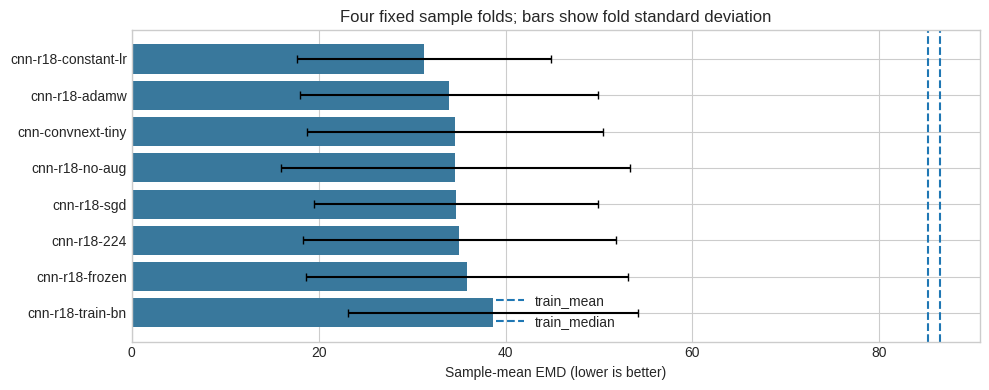

In [6]:
results, baselines, predictions = collect_results()
display(baselines.round(3))
display(results[['experiment','cv_emd','fold_std','gpu_hours','peak_gpu_mb','epochs_per_fold','public_lb','private_lb']].round(3))
fig = plot_scores(results,baselines)
fig.savefig(ROOT/'results/cnn_scores.png',dpi=150)
plt.show()

## 6. Learning curves and hypotheses

Each line is one fold. Early stop can give different line lengths.
The order checks below describe this CV result. They are not significance tests.
The optimizer-speed prediction also needs these curves, not just the last score.

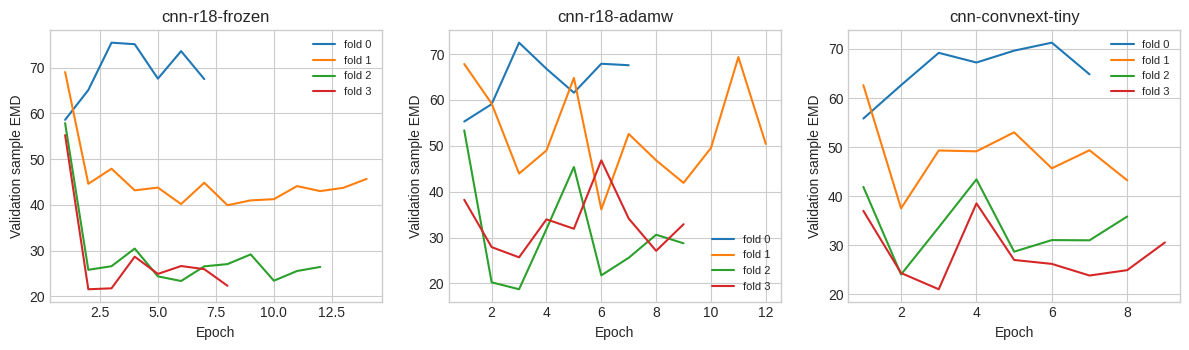

,hypothesis,comparison,CV_order_matches_prediction
0,H-CNN-01,Frozen image model vs median baseline,True
1,H-CNN-02,Fine-tuning vs frozen encoder,True
2,H-CNN-03,AdamW recipe vs SGD recipe,True
3,H-CNN-04,Frozen BN vs updated BN,True
4,H-CNN-05,Light augmentation vs none,True
5,H-CNN-06,Warmup/cosine recipe vs constant LR,False
6,H-CNN-07,288 px vs 224 px,True
7,H-CNN-08,ConvNeXt vs tuned ResNet,False


Frozen ResNet EMD is 35.858; tuned ResNet EMD is 33.956. Tuning helps here, but the gain is small.
AdamW recipe: 33.956; SGD recipe: 34.711. The score gap does not isolate optimizer choice or prove learning speed.
Frozen BN stats: 33.956; updated BN stats: 38.640. This fits the concern about running statistics from related tile batches.
Light augmentation: 33.956; no augmentation: 34.633. Light augmentation helps in this recipe.
Warmup/cosine: 33.956; constant LR: 31.287. The schedule prediction was wrong. A full LR from the start works better in this short run; many best checkpoints are early.
288 px: 33.956; 224 px: 35.051. Compare this gap with fold variation before claiming that more pixels help.
ConvNeXt-Tiny: 34.625; matched ResNet recipe: 33.956. The expected architecture gain did not hold. More capacity and different pretrained features do not ensure a gain on 18 train samples per fold.


In [7]:
fig = plot_learning()
fig.savefig(ROOT/'results/cnn_learning.png',dpi=150)
plt.show()
outcomes = hypothesis_outcomes(results)
display(outcomes)
outcomes.to_csv(ROOT/'results/cnn_hypothesis_checks.csv',index=False)
for line in interpret_results(results):
    print(line)

## 7. Soil groups and errors

Fine grains can be too small to see. Labels measure full sample mass, not just the visible top surface.
Local CNN filters can learn texture with few samples. A tile can still miss large grains or the full mix.
Here we check actual errors, rather than assuming a larger CNN is always better.

soil_group,fine,gravel,sand
experiment,,,
cnn-convnext-tiny,46.558,23.112,41.808
cnn-r18-224,49.858,26.637,33.200
cnn-r18-adamw,43.728,24.050,40.716
cnn-r18-constant-lr,36.170,25.912,35.445
cnn-r18-frozen,49.521,26.493,37.086
cnn-r18-no-aug,52.390,22.133,36.834
cnn-r18-sgd,43.827,24.996,41.885
cnn-r18-train-bn,65.528,23.479,35.065


Selected by four-fold OOF EMD: cnn-r18-constant-lr


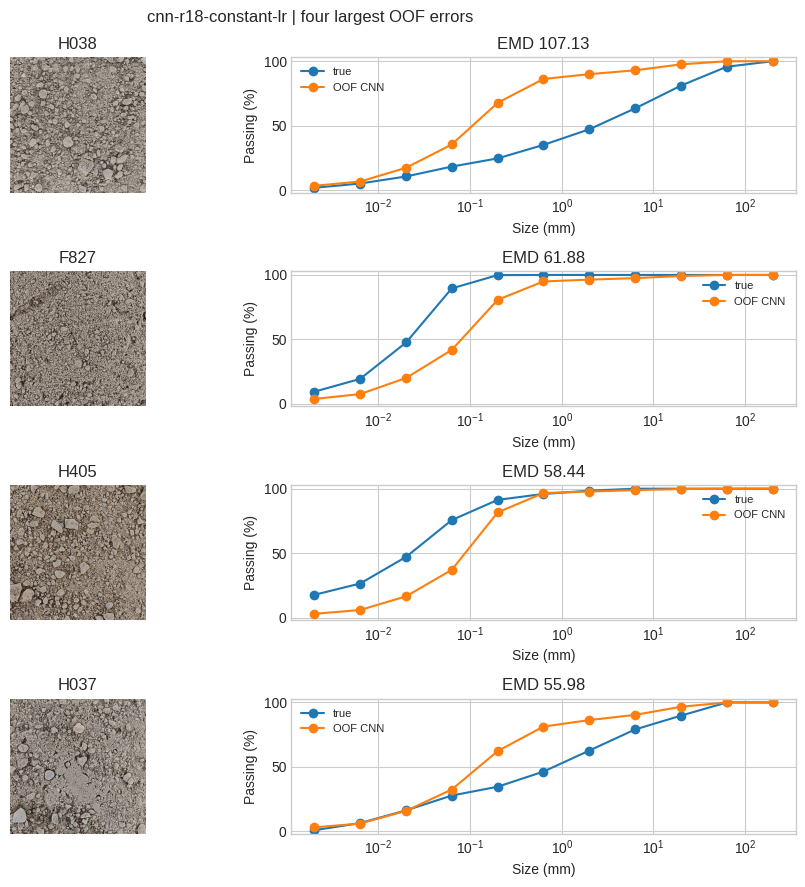

In [8]:
best = results.iloc[0].experiment
errors = pd.read_csv(ROOT/'results/cnn_group_errors.csv')
display(errors.pivot(index='experiment',columns='soil_group',values='mean_emd').round(3))
print('Selected by four-fold OOF EMD:',best)
fig = plot_failures(best,predictions[best])
fig.savefig(ROOT/'results/cnn_failures.png',dpi=150)
plt.show()

## 8. Save the report

Each fold has an online W&B run with metrics and a model artifact.
The combined CV tables stay in Kaggle Outputs. No extra W&B summary runs are created.


In [9]:
report_path = write_report(results,baselines)
display(pd.read_csv(ROOT/'results/cnn_checkpoints.csv'))
print('Report:',report_path)

hypotheses = (code_root/'HYPOTHESES.md').read_text()
(ROOT/'HYPOTHESES.md').write_text(
    hypotheses + '\n\n## This Kaggle run\n\n' + report_path.read_text()
)


,experiment,fold,wandb_run,artifact
0,cnn-r18-frozen,0,https://wandb.ai/public-team/soil-grain-size/r...,public-team/soil-grain-size/cnn-r18-frozen-fol...
1,cnn-r18-frozen,1,https://wandb.ai/public-team/soil-grain-size/r...,public-team/soil-grain-size/cnn-r18-frozen-fol...
2,cnn-r18-frozen,2,https://wandb.ai/public-team/soil-grain-size/r...,public-team/soil-grain-size/cnn-r18-frozen-fol...
3,cnn-r18-frozen,3,https://wandb.ai/public-team/soil-grain-size/r...,public-team/soil-grain-size/cnn-r18-frozen-fol...
4,cnn-r18-adamw,0,https://wandb.ai/public-team/soil-grain-size/r...,public-team/soil-grain-size/cnn-r18-adamw-fold...
5,cnn-r18-adamw,1,https://wandb.ai/public-team/soil-grain-size/r...,public-team/soil-grain-size/cnn-r18-adamw-fold...
6,cnn-r18-adamw,2,https://wandb.ai/public-team/soil-grain-size/r...,public-team/soil-grain-size/cnn-r18-adamw-fold...
7,cnn-r18-adamw,3,https://wandb.ai/public-team/soil-grain-size/r...,public-team/soil-grain-size/cnn-r18-adamw-fold...
8,cnn-r18-sgd,0,https://wandb.ai/public-team/soil-grain-size/r...,public-team/soil-grain-size/cnn-r18-sgd-fold-0:v2
9,cnn-r18-sgd,1,https://wandb.ai/public-team/soil-grain-size/r...,public-team/soil-grain-size/cnn-r18-sgd-fold-1:v2


Report: /kaggle/working/part1_cnn/results/cnn_report.md


10904

## 9. Test prediction status

The saved submission averages the selected recipe's four fold models.
OOF scores one held-out model per sample. It does not score that four-model test ensemble.
No competition submission was made. Public LB is not submitted and private LB is not available.

The inference script accepts photos, supplied PPM, and saved model folders.
It can build the model without downloading ImageNet weights again.

In [10]:
from soilcv.curves import make_submission
selection = json.loads((ROOT/'results/selection.json').read_text())
submission = pd.read_csv(ROOT/'results/cnn_submission.csv')
template = pd.DataFrame(json.loads((ROOT/'template.json').read_text()))
make_submission(submission,template)
print(selection)
display(submission.head())
print('Submission shape:',submission.shape)

{'selected_experiment': 'cnn-r18-constant-lr', 'selection_rule': 'lowest sample-level four-fold OOF EMD', 'cv_emd': 31.286982117878456, 'test_prediction': 'mean of four fold models', 'note': 'OOF evaluates individual held-out fold models, not this four-model test ensemble.', 'leaderboard_submission_made': False}


,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,HPC_Airbus BS6-3,3.504999,7.444268,19.014198,48.278093,84.152623,98.310757,98.893980,99.326445,99.791905,99.997208,100.0
1,HPC_Audorfring,1.996710,4.331147,10.799605,24.080557,42.572296,59.175041,69.537566,80.518186,93.715154,99.959004,100.0
2,HPC_Muenster_BS6_9_0-10m,0.899652,1.992383,4.688925,9.839562,16.257876,26.784100,41.704710,62.804605,88.824918,99.941502,100.0
3,HPC_Airbus BS10-4bis7,3.448745,7.390985,18.858683,48.927442,85.732636,98.834334,99.244332,99.526588,99.848338,99.998097,100.0
4,HPC_Airbus BS12-5bis8,3.587964,7.611680,19.426738,49.109516,84.509090,98.397042,98.937485,99.338076,99.792961,99.997264,100.0


Submission shape: (10, 12)


## Limits and next step

All recipes use one fixed four-fold split. We tried eight recipes on a very small dataset.
A small score gain is not proof that a recipe is better on new soils.
We fix seeds, but GPU math is not fully deterministic. A new run can give another score.
The same EDA showed split sensitivity and a camera change between train and test.
Absolute PPM remains an estimate.

Keep this CNN result and the OOF files as references for the ViT and SSL parts.
AI helped write and run this code. Read it before the defense.

## 10. Kaggle Outputs

The study folder has best/last checkpoints, inference weights, OOF and test curves,
configs, logs, graphs, the report, source code, folds, and environment files.
`output_manifest.json` lists files and their hashes.
`submission.csv` is also saved at the top level. No competition submission is sent.


In [11]:
output_folder = export_outputs()
print('Full study:', output_folder)
print('Submission:', ROOT.parent/'submission.csv')
print('W&B:', 'https://wandb.ai/public-team/soil-grain-size')


Saved 491 study files in /kaggle/working/part1_cnn
Full study: /kaggle/working/part1_cnn
Submission: /kaggle/working/submission.csv
W&B: https://wandb.ai/public-team/soil-grain-size
